In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit


In [10]:
data = sm.datasets.sunspots.load_pandas().data

sunspots = data["SUNACTIVITY"].values

# Create lagged features
def add_lagged_features(data, lag=12):
    X, y = [], []

    for i in range(lag, len(data)):
        X.append(data[i-lag:i])
        y.append(data[i])

    return np.array(X), np.array(y)

X, y = add_lagged_features(sunspots, lag=12)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)

# Scale inputs
x_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Scale targets
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

In [11]:
def create_and_fit_mlp(activation_function):

    # 3 hidden layers, 50 neurons each
    mlp = MLPRegressor(
        hidden_layer_sizes=(50, 50, 50),
        activation=activation_function,
        solver="adam",
        max_iter=2500,
        random_state=42
    )

    # Train
    mlp.fit(X_train_scaled, y_train_scaled)

    # Predict
    y_pred_scaled = mlp.predict(X_test_scaled)

    # Convert back to original sunspot values
    y_pred = y_scaler.inverse_transform(
        y_pred_scaled.reshape(-1, 1)
    ).ravel()

    # Evaluate
    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    print(f"{activation_function} MLP RMSE: {rmse:.4f}")
    print(f"{activation_function} MLP MAE: {mae:.4f}")

    return y_pred, rmse, mae


# Train models
y_pred_relu, rmse_relu, mae_relu = create_and_fit_mlp("relu")
y_pred_tanh, rmse_tanh, mae_tanh = create_and_fit_mlp("tanh")
y_pred_logistic, rmse_logistic, mae_logistic = create_and_fit_mlp("logistic")

relu MLP RMSE: 19.5369
relu MLP MAE: 15.8780
tanh MLP RMSE: 21.2120
tanh MLP MAE: 15.3224
logistic MLP RMSE: 21.3043
logistic MLP MAE: 16.1994


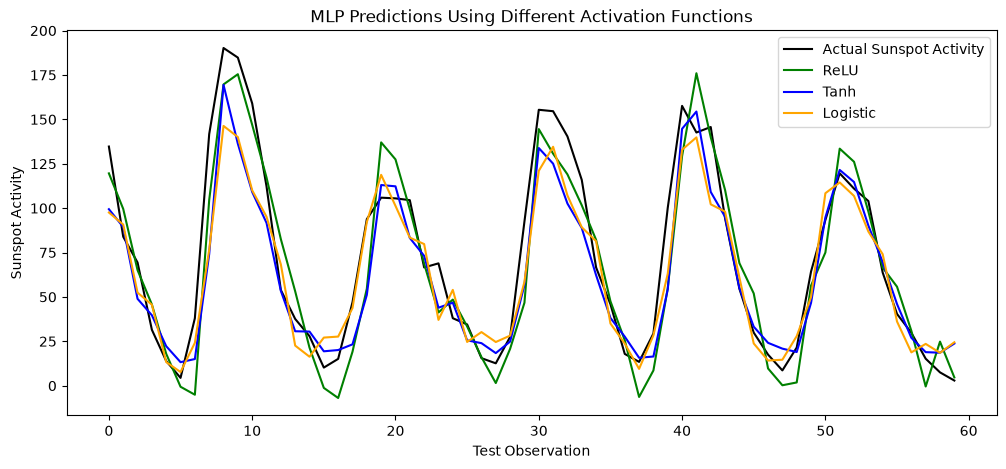

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(y_test, label="Actual Sunspot Activity", color="black")

plt.plot(y_pred_relu, label="ReLU", color="green")
plt.plot(y_pred_tanh, label="Tanh", color="blue")
plt.plot(y_pred_logistic, label="Logistic", color="orange")

plt.legend()
plt.title("MLP Predictions Using Different Activation Functions")
plt.xlabel("Test Observation")
plt.ylabel("Sunspot Activity")
plt.show()

  Activation       RMSE        MAE
0       ReLU  19.536947  15.877979
1       Tanh  21.211985  15.322374
2   Logistic  21.304277  16.199416


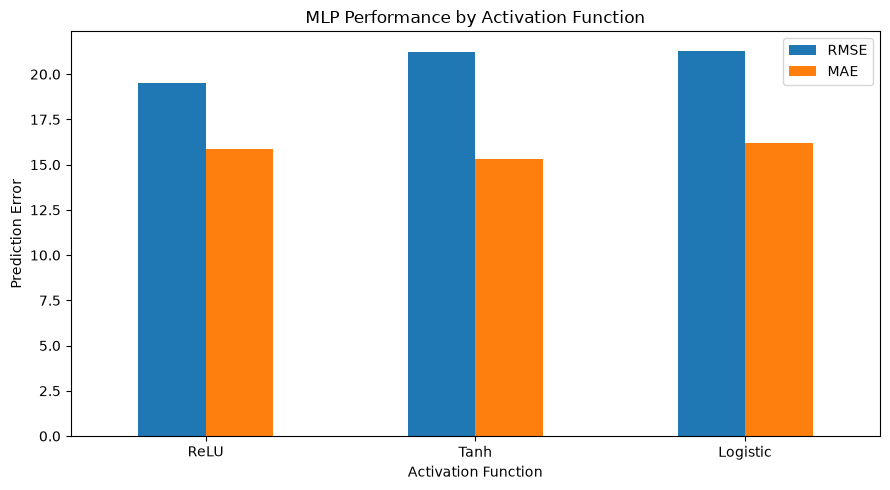

In [13]:
results = pd.DataFrame({
    "Activation": ["ReLU", "Tanh", "Logistic"],
    "RMSE": [rmse_relu, rmse_tanh, rmse_logistic],
    "MAE": [mae_relu, mae_tanh, mae_logistic]
})

print(results)

results.set_index("Activation").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("MLP Performance by Activation Function")
plt.ylabel("Prediction Error")
plt.xlabel("Activation Function")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()